In [1]:
# ============================================================
# HOMEWORK 3.1 - PART IV
# COMPARE N > M AND N < M
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from scipy.optimize import linprog


# ============================================================
# HELPER: EUCLIDEAN COST MATRIX
# ============================================================

def get_cost_matrix(
    source_locations,
    target_locations
):

    difference = (

        source_locations[:, None, :]

        -

        target_locations[None, :, :]
    )


    return np.sqrt(

        np.sum(
            difference**2,
            axis=2
        )
    )


# ============================================================
# HELPER: EXHAUSTIVE MONGE SEARCH
# ============================================================

def solve_monge(
    cost_matrix,
    supply,
    demand
):

    N = len(
        supply
    )

    M = len(
        demand
    )


    possible_maps = list(

        product(
            range(M),
            repeat=N
        )
    )


    feasible_maps = []


    for T in possible_maps:

        received = np.zeros(
            M
        )


        for i in range(N):

            received[
                T[i]
            ] += supply[i]


        if np.allclose(
            received,
            demand
        ):

            cost = sum(

                supply[i]
                *
                cost_matrix[
                    i,
                    T[i]
                ]

                for i in range(N)
            )


            feasible_maps.append({

                "Map":
                    T,

                "Received":
                    received.copy(),

                "Cost":
                    cost

            })


    if len(feasible_maps) == 0:

        best = None

    else:

        best = min(

            feasible_maps,

            key=lambda item:
                item["Cost"]
        )


    return (
        possible_maps,
        feasible_maps,
        best
    )


# ============================================================
# HELPER: KANTOROVICH LINEAR PROGRAM
# ============================================================

def solve_kantorovich(
    cost_matrix,
    supply,
    demand
):

    N = len(
        supply
    )

    M = len(
        demand
    )


    number_of_variables = (
        N * M
    )


    A_eq = []

    b_eq = []


    # Supply constraints

    for i in range(N):

        row = np.zeros(
            number_of_variables
        )


        for j in range(M):

            row[
                i * M + j
            ] = 1.0


        A_eq.append(
            row
        )

        b_eq.append(
            supply[i]
        )


    # Demand constraints

    for j in range(M):

        row = np.zeros(
            number_of_variables
        )


        for i in range(N):

            row[
                i * M + j
            ] = 1.0


        A_eq.append(
            row
        )

        b_eq.append(
            demand[j]
        )


    result = linprog(

        c=cost_matrix.flatten(),

        A_eq=np.array(
            A_eq
        ),

        b_eq=np.array(
            b_eq
        ),

        bounds=[
            (0, None)
            for _ in range(
                number_of_variables
            )
        ],

        method="highs"
    )


    if not result.success:

        raise RuntimeError(
            result.message
        )


    gamma = result.x.reshape(
        N,
        M
    )


    # Verify row sums

    assert np.allclose(

        np.sum(
            gamma,
            axis=1
        ),

        supply
    )


    # Verify column sums

    assert np.allclose(

        np.sum(
            gamma,
            axis=0
        ),

        demand
    )


    # Verify nonnegative

    assert np.all(
        gamma >= -1e-10
    )


    # Verify objective

    manual_cost = np.sum(

        gamma
        *
        cost_matrix
    )


    assert np.isclose(

        result.fun,

        manual_cost
    )


    return (
        gamma,
        result.fun
    )


# ============================================================
# CASE 1
# N > M
# ============================================================

case1_bakeries = np.array([
    [0.0, 0.0],
    [0.0, 6.0],
    [8.0, 0.0],
    [8.0, 6.0]
])


case1_supply = np.array([
    2.0,
    2.0,
    2.0,
    2.0
])


case1_cafes = np.array([
    [0.0, 3.0],
    [7.0, 0.0],
    [7.0, 6.0]
])


case1_demand = np.array([
    4.0,
    2.0,
    2.0
])


N1 = len(
    case1_supply
)

M1 = len(
    case1_demand
)


assert N1 > M1


assert np.isclose(

    np.sum(
        case1_supply
    ),

    np.sum(
        case1_demand
    )
)


case1_cost = get_cost_matrix(

    case1_bakeries,

    case1_cafes
)


print("=" * 70)

print(
    "CASE 1: N > M"
)

print("=" * 70)

print(
    "N =",
    N1
)

print(
    "M =",
    M1
)

print(
    "Supply =",
    case1_supply
)

print(
    "Demand =",
    case1_demand
)

print()

print(
    "Cost matrix:"
)

print(

    np.round(
        case1_cost,
        4
    )
)


# ============================================================
# CASE 1 MONGE
# ============================================================

(
    case1_all_maps,
    case1_feasible_maps,
    case1_best_monge

) = solve_monge(

    case1_cost,

    case1_supply,

    case1_demand
)


print()

print("-" * 70)

print(
    "CASE 1 MONGE RESULTS"
)

print("-" * 70)

print(
    "Total possible maps =",
    len(case1_all_maps)
)

print(
    "Number of feasible maps =",
    len(case1_feasible_maps)
)

print(
    "Optimal Monge map =",
    case1_best_monge["Map"]
)

print(
    "Optimal Monge cost =",
    case1_best_monge["Cost"]
)


# Python map:
#
# (0,0,1,2)
#
# means
#
# B1 -> C1
# B2 -> C1
# B3 -> C2
# B4 -> C3


# ============================================================
# CASE 1 KANTOROVICH
# ============================================================

case1_gamma, case1_k_cost = (
    solve_kantorovich(

        case1_cost,

        case1_supply,

        case1_demand
    )
)


print()

print("-" * 70)

print(
    "CASE 1 KANTOROVICH RESULTS"
)

print("-" * 70)

print(
    "Optimal gamma:"
)

print(
    np.round(
        case1_gamma,
        6
    )
)

print(
    "Optimal Kantorovich cost =",
    case1_k_cost
)


# ============================================================
# VERIFY CASE 1 EXPECTED RESULT
# ============================================================

assert len(
    case1_all_maps
) == 3**4


assert len(
    case1_feasible_maps
) == 12


assert case1_best_monge[
    "Map"
] == (
    0,
    0,
    1,
    2
)


assert np.isclose(

    case1_best_monge[
        "Cost"
    ],

    16.0
)


assert np.isclose(

    case1_k_cost,

    16.0
)


assert np.isclose(

    case1_best_monge[
        "Cost"
    ],

    case1_k_cost
)


# ============================================================
# CHECK IF KANTOROVICH PLAN IS MONGE-LIKE
# ============================================================

case1_positive_per_row = np.sum(

    case1_gamma > 1e-8,

    axis=1
)


case1_is_monge_like = np.all(

    case1_positive_per_row
    ==
    1
)


print()

print(
    "Positive destinations per bakery =",
    case1_positive_per_row
)

print(
    "Is optimal Kantorovich plan induced "
    "by a Monge map?",
    case1_is_monge_like
)


assert case1_is_monge_like


print()

print(
    "PASS: Case 1 has an admissible Monge map."
)

print(
    "PASS: Optimal Monge cost = 16."
)

print(
    "PASS: Optimal Kantorovich cost = 16."
)

print(
    "PASS: The optimal Kantorovich solution "
    "does not require splitting."
)

CASE 1: N > M
N = 4
M = 3
Supply = [2. 2. 2. 2.]
Demand = [4. 2. 2.]

Cost matrix:
[[3.     7.     9.2195]
 [3.     9.2195 7.    ]
 [8.544  1.     6.0828]
 [8.544  6.0828 1.    ]]

----------------------------------------------------------------------
CASE 1 MONGE RESULTS
----------------------------------------------------------------------
Total possible maps = 81
Number of feasible maps = 12
Optimal Monge map = (0, 0, 1, 2)
Optimal Monge cost = 16.0

----------------------------------------------------------------------
CASE 1 KANTOROVICH RESULTS
----------------------------------------------------------------------
Optimal gamma:
[[2. 0. 0.]
 [2. 0. 0.]
 [0. 2. 0.]
 [0. 0. 2.]]
Optimal Kantorovich cost = 16.0

Positive destinations per bakery = [1 1 1 1]
Is optimal Kantorovich plan induced by a Monge map? True

PASS: Case 1 has an admissible Monge map.
PASS: Optimal Monge cost = 16.
PASS: Optimal Kantorovich cost = 16.
PASS: The optimal Kantorovich solution does not require splitti

In [2]:
# ============================================================
# CASE 2
# N < M
# REUSE ORIGINAL SYNTHETIC CITY
# ============================================================

case2_bakeries = np.array([
    [1.0, 1.0],
    [7.0, 1.0],
    [4.0, 7.0]
])


case2_supply = np.array([
    5.0,
    6.0,
    4.0
])


case2_cafes = np.array([
    [2.0, 3.0],
    [6.0, 3.0],
    [3.0, 6.0],
    [7.0, 6.0]
])


case2_demand = np.array([
    3.0,
    4.0,
    5.0,
    3.0
])


N2 = len(
    case2_supply
)

M2 = len(
    case2_demand
)


assert N2 < M2


case2_cost = get_cost_matrix(

    case2_bakeries,

    case2_cafes
)


print()

print("=" * 70)

print(
    "CASE 2: N < M"
)

print("=" * 70)

print(
    "N =",
    N2
)

print(
    "M =",
    M2
)

print(
    "Supply =",
    case2_supply
)

print(
    "Demand =",
    case2_demand
)


# ============================================================
# CASE 2 MONGE
# ============================================================

(
    case2_all_maps,
    case2_feasible_maps,
    case2_best_monge

) = solve_monge(

    case2_cost,

    case2_supply,

    case2_demand
)


print()

print("-" * 70)

print(
    "CASE 2 MONGE RESULTS"
)

print("-" * 70)

print(
    "Total possible maps =",
    len(case2_all_maps)
)

print(
    "Number of feasible maps =",
    len(case2_feasible_maps)
)

print(
    "Best Monge map =",
    case2_best_monge
)


assert len(
    case2_all_maps
) == 4**3


assert len(
    case2_feasible_maps
) == 0


assert case2_best_monge is None


# ============================================================
# CASE 2 KANTOROVICH
# ============================================================

case2_gamma, case2_k_cost = (
    solve_kantorovich(

        case2_cost,

        case2_supply,

        case2_demand
    )
)


print()

print("-" * 70)

print(
    "CASE 2 KANTOROVICH RESULTS"
)

print("-" * 70)

print(
    "Optimal gamma:"
)

print(
    np.round(
        case2_gamma,
        6
    )
)

print(
    "Optimal Kantorovich cost =",
    case2_k_cost
)


# ============================================================
# CHECK FOR MASS SPLITTING
# ============================================================

case2_positive_per_row = np.sum(

    case2_gamma > 1e-8,

    axis=1
)


case2_split_rows = (

    case2_positive_per_row
    >
    1
)


print()

print(
    "Positive destinations per bakery =",
    case2_positive_per_row
)

print(
    "Does each bakery split mass? =",
    case2_split_rows
)


assert np.any(
    case2_split_rows
)


print()

print(
    "PASS: Case 2 has no admissible Monge map."
)

print(
    "PASS: Case 2 Kantorovich problem is feasible."
)

print(
    "PASS: The Kantorovich solution splits "
    "mass from at least one bakery."
)



CASE 2: N < M
N = 3
M = 4
Supply = [5. 6. 4.]
Demand = [3. 4. 5. 3.]

----------------------------------------------------------------------
CASE 2 MONGE RESULTS
----------------------------------------------------------------------
Total possible maps = 64
Number of feasible maps = 0
Best Monge map = None

----------------------------------------------------------------------
CASE 2 KANTOROVICH RESULTS
----------------------------------------------------------------------
Optimal gamma:
[[3. 0. 2. 0.]
 [0. 4. 0. 2.]
 [0. 0. 3. 1.]]
Optimal Kantorovich cost = 43.8277238040552

Positive destinations per bakery = [2 2 2]
Does each bakery split mass? = [ True  True  True]

PASS: Case 2 has no admissible Monge map.
PASS: Case 2 Kantorovich problem is feasible.
PASS: The Kantorovich solution splits mass from at least one bakery.



FINAL COMPARISON

         Case  N  M  Monge_Feasible  Monge_Cost  Kantorovich_Cost  Kantorovich_Splits_Mass
Case 1: N > M  4  3            True        16.0         16.000000                    False
Case 2: N < M  3  4           False         NaN         43.827724                     True


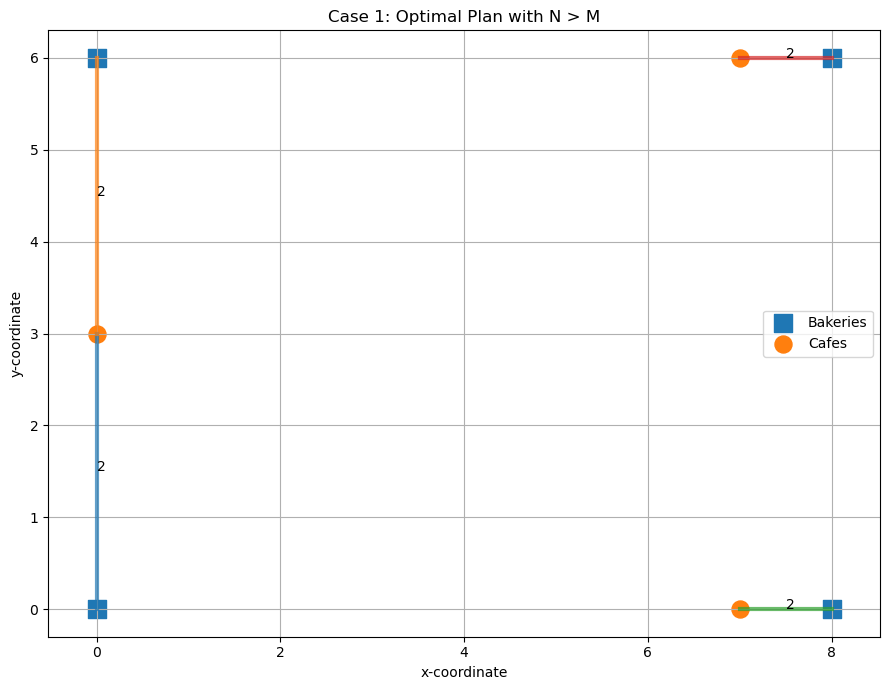

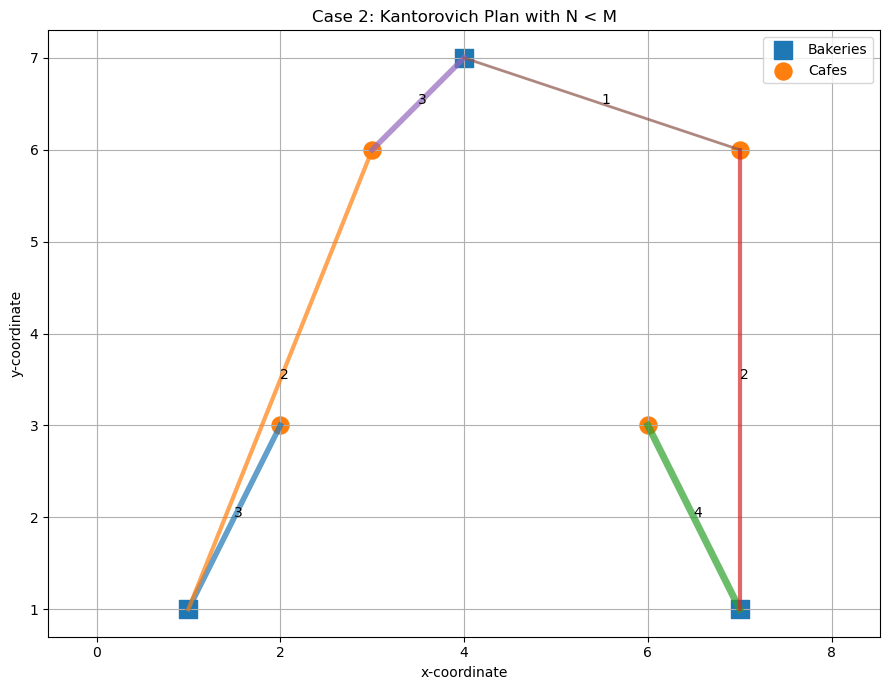


FINAL VERIFICATION
PASS: Case 1 has N > M.
PASS: Case 1 Monge solution exists.
PASS: Case 1 Monge and Kantorovich optimal costs agree.
PASS: Case 2 has N < M.
PASS: Case 2 Monge solution does not exist.
PASS: Case 2 Kantorovich solution exists.
PASS: Case 2 requires mass splitting.


In [3]:
# ============================================================
# SUMMARY TABLE
# ============================================================

summary = pd.DataFrame({

    "Case": [
        "Case 1: N > M",
        "Case 2: N < M"
    ],

    "N": [
        N1,
        N2
    ],

    "M": [
        M1,
        M2
    ],

    "Monge_Feasible": [
        True,
        False
    ],

    "Monge_Cost": [
        case1_best_monge["Cost"],
        np.nan
    ],

    "Kantorovich_Cost": [
        case1_k_cost,
        case2_k_cost
    ],

    "Kantorovich_Splits_Mass": [
        not case1_is_monge_like,
        np.any(case2_split_rows)
    ]

})


print()

print("=" * 70)

print(
    "FINAL COMPARISON"
)

print("=" * 70)

print()

print(
    summary.to_string(
        index=False
    )
)


# ============================================================
# PLOT CASE 1 OPTIMAL PLAN
# ============================================================

plt.figure(
    figsize=(9, 7)
)


plt.scatter(

    case1_bakeries[:, 0],

    case1_bakeries[:, 1],

    s=150,

    marker="s",

    label="Bakeries"
)


plt.scatter(

    case1_cafes[:, 0],

    case1_cafes[:, 1],

    s=150,

    marker="o",

    label="Cafes"
)


for i in range(N1):

    for j in range(M1):

        amount = case1_gamma[
            i,
            j
        ]


        if amount > 1e-8:

            plt.plot(

                [
                    case1_bakeries[i, 0],
                    case1_cafes[j, 0]
                ],

                [
                    case1_bakeries[i, 1],
                    case1_cafes[j, 1]
                ],

                linewidth=(
                    1
                    +
                    amount
                ),

                alpha=0.7
            )


            midpoint = (

                case1_bakeries[i]

                +

                case1_cafes[j]

            ) / 2


            plt.annotate(

                f"{amount:.0f}",

                midpoint
            )


plt.xlabel(
    "x-coordinate"
)

plt.ylabel(
    "y-coordinate"
)

plt.title(
    "Case 1: Optimal Plan with N > M"
)

plt.grid(
    True
)

plt.legend()

plt.axis(
    "equal"
)

plt.tight_layout()

plt.savefig(
    "case1_N_greater_M_plan.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT CASE 2 KANTOROVICH PLAN
# ============================================================

plt.figure(
    figsize=(9, 7)
)


plt.scatter(

    case2_bakeries[:, 0],

    case2_bakeries[:, 1],

    s=150,

    marker="s",

    label="Bakeries"
)


plt.scatter(

    case2_cafes[:, 0],

    case2_cafes[:, 1],

    s=150,

    marker="o",

    label="Cafes"
)


for i in range(N2):

    for j in range(M2):

        amount = case2_gamma[
            i,
            j
        ]


        if amount > 1e-8:

            plt.plot(

                [
                    case2_bakeries[i, 0],
                    case2_cafes[j, 0]
                ],

                [
                    case2_bakeries[i, 1],
                    case2_cafes[j, 1]
                ],

                linewidth=(
                    1
                    +
                    amount
                ),

                alpha=0.7
            )


            midpoint = (

                case2_bakeries[i]

                +

                case2_cafes[j]

            ) / 2


            plt.annotate(

                f"{amount:.0f}",

                midpoint
            )


plt.xlabel(
    "x-coordinate"
)

plt.ylabel(
    "y-coordinate"
)

plt.title(
    "Case 2: Kantorovich Plan with N < M"
)

plt.grid(
    True
)

plt.legend()

plt.axis(
    "equal"
)

plt.tight_layout()

plt.savefig(
    "case2_N_less_M_kantorovich_plan.png",
    dpi=300
)

plt.show()


# ============================================================
# FINAL AUTOMATIC VERIFICATION
# ============================================================

print()

print("=" * 70)

print(
    "FINAL VERIFICATION"
)

print("=" * 70)

print(
    "PASS: Case 1 has N > M."
)

print(
    "PASS: Case 1 Monge solution exists."
)

print(
    "PASS: Case 1 Monge and Kantorovich "
    "optimal costs agree."
)

print(
    "PASS: Case 2 has N < M."
)

print(
    "PASS: Case 2 Monge solution does not exist."
)

print(
    "PASS: Case 2 Kantorovich solution exists."
)

print(
    "PASS: Case 2 requires mass splitting."
)